# Độ chính xác kiểm tra theo số mô hình thành phần trên dữ liệu ung thư vú (mục 9.2.2)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
sizes = [1, 2, 3, 5, 10, 20, 50, 100, 200, 400]
makers = [('Random Forest', lambda n: RandomForestClassifier(n_estimators=n, random_state=0, n_jobs=-1)),
          ('AdaBoost (cây 1 tầng)', lambda n: AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=n, random_state=0)),
          ('Gradient Boosting', lambda n: GradientBoostingClassifier(n_estimators=n, random_state=0))]

Vẽ hình và lưu ảnh.

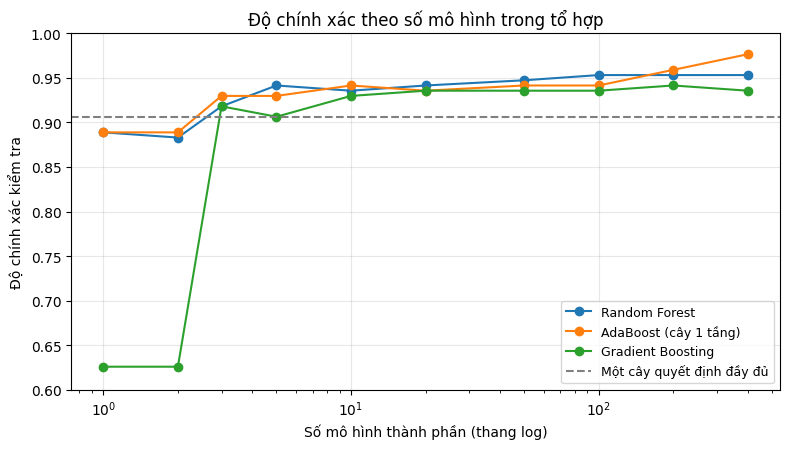

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.6))
for name, make_model in makers:
    ax.plot(sizes, [make_model(n).fit(X_train, y_train).score(X_test, y_test) for n in sizes], 'o-', label=name)
tree_score = DecisionTreeClassifier(random_state=0).fit(X_train, y_train).score(X_test, y_test)
ax.axhline(tree_score, color='gray', ls='--', label='Một cây quyết định đầy đủ')
ax.set_xscale('log')
ax.set_xlabel('Số mô hình thành phần (thang log)'); ax.set_ylabel('Độ chính xác kiểm tra')
ax.set_title('Độ chính xác theo số mô hình trong tổ hợp')
ax.set_ylim(0.6, 1.0); ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / 'n_estimators.png', dpi=150)